In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cosine
from scipy.signal import find_peaks
from src.rainfall import Region, CropRule

In [2]:
# Monthly rainfall data (mm), January to December
rainfall_data = {
    "Kampala": [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130],
    "Gulu":    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90]
}

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Convert the rainfall lists to NumPy arrays
rainfall_arrays = {
    region: np.array(values, dtype=float)
    for region, values in rainfall_data.items()
}

# Display the rainfall data as a table
rainfall_df = pd.DataFrame(rainfall_arrays, index=months)
rainfall_df.index.name = "Month"

rainfall_df


,Kampala,Gulu,Mbarara
Month,,,
Jan,120.0,8.0,70.0
Feb,140.0,25.0,85.0
Mar,180.0,75.0,120.0
Apr,200.0,160.0,140.0
May,220.0,190.0,90.0
Jun,180.0,145.0,25.0
Jul,90.0,170.0,20.0
Aug,70.0,215.0,55.0
Sep,60.0,175.0,100.0


In [3]:
# Create Region objects
regions = {
    name: Region(name, values)
    for name, values in rainfall_arrays.items()
}

# Summarise rainfall statistics
rainfall_summary = pd.DataFrame([
    {
        "Region": region.name,
        "Annual rainfall (mm)": region.annual_total(),
        "Mean monthly rainfall (mm)": region.mean_rainfall(),
        "Wettest month": region.wettest_month(),
        "Driest month": region.driest_month(),
        "Rainfall CV": region.coefficient_of_variation()
    }
    for region in regions.values()
])

rainfall_summary.round(3)


,Region,Annual rainfall (mm),Mean monthly rainfall (mm),Wettest month,Driest month,Rainfall CV
0,Kampala,1600.0,133.333,May,Sep,0.372
1,Gulu,1388.0,115.667,Aug,Jan,0.614
2,Mbarara,1040.0,86.667,Apr,Jul,0.425


In [4]:
crop_rules = {
    "Maize": CropRule("maize", 50, 150),
    "Beans": CropRule("beans", 40, 120),
    "Coffee": CropRule("coffee", 80, 180)
}

# Check that the rules classify rainfall as expected
for crop_name, rule in crop_rules.items():
    print(
        f"{crop_name}: "
        f"30 mm -> {rule.classify(30)}; "
        f"100 mm -> {rule.classify(100)}; "
        f"200 mm -> {rule.classify(200)}"
    )

Maize: 30 mm -> Drought risk; 100 mm -> Good for maize; 200 mm -> Waterlogging risk
Beans: 30 mm -> Drought risk; 100 mm -> Good for beans; 200 mm -> Waterlogging risk
Coffee: 30 mm -> Drought risk; 100 mm -> Good for coffee; 200 mm -> Waterlogging risk


The monthly rainfall thresholds used in this analysis are illustrative screening assumptions rather than values directly established by published agronomic studies. Published crop water requirements are generally expressed over an entire growing season or year and vary according to crop variety, growth stage, soil conditions, evapotranspiration, and rainfall distribution. Consequently, these requirements cannot be translated directly into fixed monthly minimum and maximum rainfall values without additional evidence. 
For instance, the Food and Agriculture Organization (FAO) estimates seasonal crop water requirements of approximately 500–800 mm for maize and 300–500 mm for beans and the Uganda Arabica Coffee Handbook indicates an annual rainfall requirement of approximately 1,200–1,800 mm, distributed over about nine months. These sources demonstrate that crop water requirements differ by crop and depend on the distribution of rainfall.
**References**
[https://www.fao.org/4/S2022E/s2022e07.htm]FAO


In [5]:

# Build a table of rainfall and crop suitability for every region and month
suitability_records = []

for region_name, rainfall_values in rainfall_data.items():
    for i, rainfall in enumerate(rainfall_values):
        record = {
            "Region": region_name,
            "Month": months[i],
            "Rainfall (mm)": rainfall
        }

        for crop_name, rule in crop_rules.items():
            record[crop_name] = rule.classify(rainfall)

        suitability_records.append(record)

suitability_df = pd.DataFrame(suitability_records)

suitability_df


,Region,Month,Rainfall (mm),Maize,Beans,Coffee
0,Kampala,Jan,120,Good for maize,Good for beans,Good for coffee
1,Kampala,Feb,140,Good for maize,Waterlogging risk,Good for coffee
2,Kampala,Mar,180,Waterlogging risk,Waterlogging risk,Good for coffee
3,Kampala,Apr,200,Waterlogging risk,Waterlogging risk,Waterlogging risk
4,Kampala,May,220,Waterlogging risk,Waterlogging risk,Waterlogging risk
5,Kampala,Jun,180,Waterlogging risk,Waterlogging risk,Good for coffee
6,Kampala,Jul,90,Good for maize,Good for beans,Good for coffee
7,Kampala,Aug,70,Good for maize,Good for beans,Drought risk
8,Kampala,Sep,60,Good for maize,Good for beans,Drought risk
9,Kampala,Oct,100,Good for maize,Good for beans,Good for coffee


In [6]:

def cosine_similarity_numpy(a: np.ndarray, b: np.ndarray) -> float:
    """Calculate cosine similarity between two numerical vectors."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if a.shape != b.shape:
        raise ValueError("Vectors must have the same shape.")

    if not np.all(np.isfinite(a)) or not np.all(np.isfinite(b)):
        raise ValueError("Vectors must contain finite values.")

    norm_product = np.linalg.norm(a) * np.linalg.norm(b)

    if norm_product == 0:
        raise ValueError("Cosine similarity is undefined for zero vectors.")

    return float(np.dot(a, b) / norm_product)


In [7]:
kampala_rain = rainfall_arrays["Kampala"]
gulu_rain = rainfall_arrays["Gulu"]

numpy_similarity = cosine_similarity_numpy(kampala_rain, gulu_rain)
scipy_similarity = 1 - cosine(kampala_rain, gulu_rain)

print(f"NumPy cosine similarity: {numpy_similarity:.6f}")
print(f"SciPy cosine similarity: {scipy_similarity:.6f}")

NumPy cosine similarity: 0.786609
SciPy cosine similarity: 0.786609


In [8]:
region_names = list(rainfall_arrays.keys())

cosine_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)
pearson_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)
euclidean_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)

for name_a in region_names:
    for name_b in region_names:
        a = rainfall_arrays[name_a]
        b = rainfall_arrays[name_b]

        cosine_matrix.loc[name_a, name_b] = (
            cosine_similarity_numpy(a, b)
        )
        pearson_matrix.loc[name_a, name_b] = np.corrcoef(a, b)[0, 1]
        euclidean_matrix.loc[name_a, name_b] = np.linalg.norm(a - b)

print("Cosine Similarity Matrix")
display(cosine_matrix.round(3))

print("Pearson Correlation Matrix")
display(pearson_matrix.round(3))

print("Euclidean Distance Matrix (mm)")
display(euclidean_matrix.round(2))


Cosine Similarity Matrix


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson Correlation Matrix


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean Distance Matrix (mm)


,Kampala,Gulu,Mbarara
Kampala,0.00,315.27,250.4
Gulu,315.27,0.00,312.8
Mbarara,250.40,312.80,0.0


Cosine similarity can rate two regions as similar even when one is much wetter than the other because it compares the shape of their rainfall patterns rather than the total amount of rainfall they receive. It measures the angle between two rainfall vectors, not the size or magnitude of those vectors.

In [9]:
season_results = []

for region_name, rainfall in rainfall_arrays.items():
    peaks, properties = find_peaks(rainfall, prominence=15)

    peak_months = [months[i] for i in peaks]
    number_of_peaks = len(peaks)

    if number_of_peaks == 1:
        pattern = "Unimodal"
    elif number_of_peaks == 2:
        pattern = "Bimodal"
    elif number_of_peaks > 2:
        pattern = "Multiple peaks"
    else:
        pattern = "No clear peak detected"

    season_results.append({
        "Region": region_name,
        "Peak months": ", ".join(peak_months) if peak_months else "None",
        "Number of peaks": number_of_peaks,
        "Detected pattern": pattern
    })

season_df = pd.DataFrame(season_results)
display(season_df)


,Region,Peak months,Number of peaks,Detected pattern
0,Kampala,May,1,Unimodal
1,Gulu,"May, Aug",2,Bimodal
2,Mbarara,"Apr, Oct",2,Bimodal


The peak detection results indicate that Kampala has one local rainfall peak in May, while Gulu has peaks in May and August, and Mbarara has peaks in April and October. These results do not fully reflect the typical rainfall regimes of Uganda, where central Uganda generally experiences two rainy seasons and northern Uganda typically experiences one prolonged rainy season. This difference may be attributed to the illustrative nature of the dataset. Therefore, these classifications should be interpreted as patterns detected in the supplied data, rather than definitive descriptions of the regions' climates.

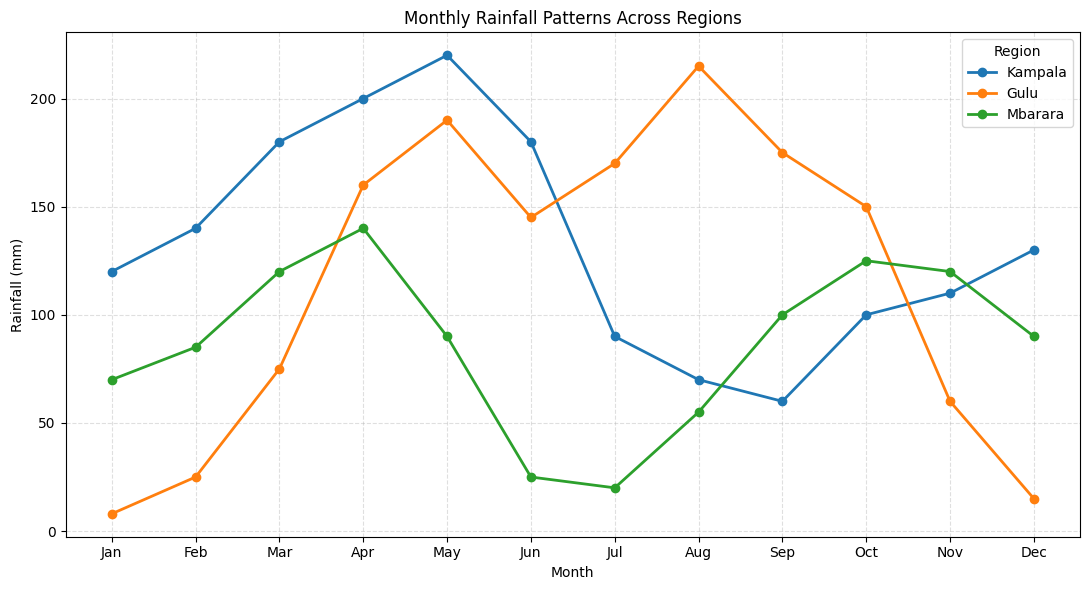

In [10]:

plt.figure(figsize=(11, 6))

for region_name, rainfall in rainfall_arrays.items():
    plt.plot(
        months,
        rainfall,
        marker="o",
        linewidth=2,
        label=region_name
    )

plt.title("Monthly Rainfall Patterns Across Regions")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.legend(title="Region")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


C:\Users\KEVINNAKITENDE\AppData\Local\Temp\ipykernel_17436\2704212301.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


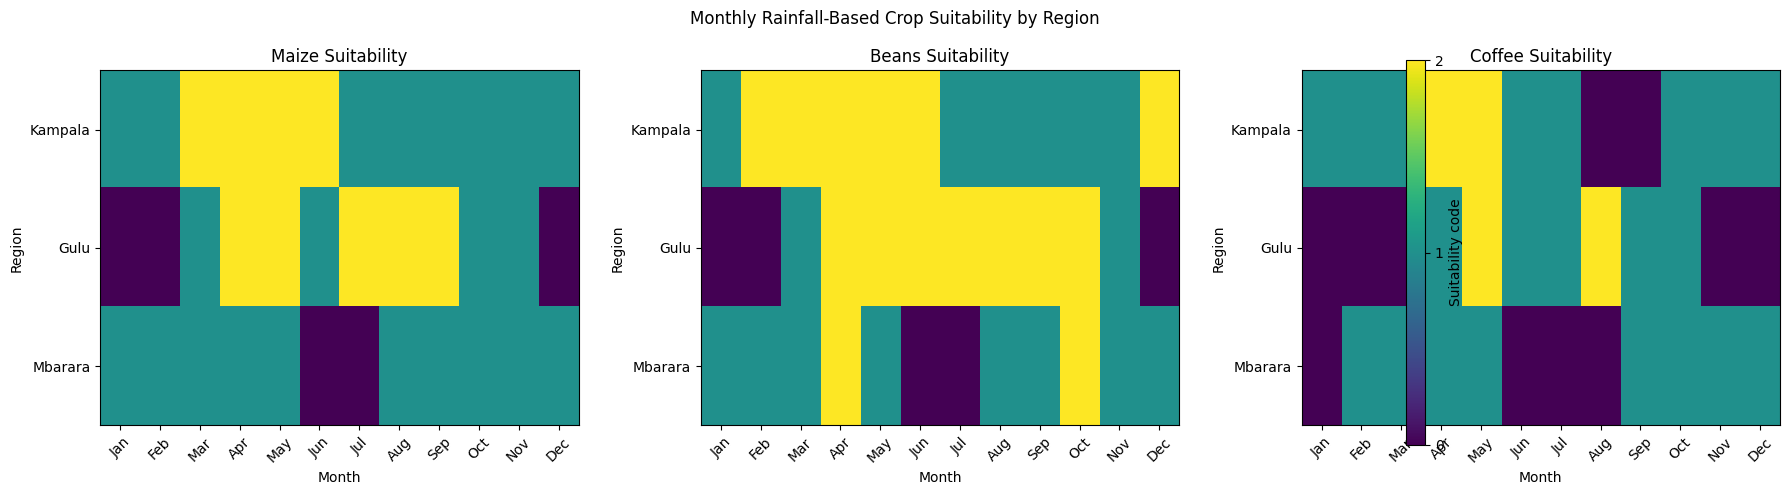

In [11]:
suitability_codes = {
    "Drought risk": 0,
    "Good for maize": 1,
    "Good for beans": 1,
    "Good for coffee": 1,
    "Waterlogging risk": 2
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5)
)

crop_names = ["Maize", "Beans", "Coffee"]

for ax, crop_name in zip(axes, crop_names):
    heatmap_data = suitability_df.pivot(
        index="Region",
        columns="Month",
        values=crop_name
    )

    heatmap_data = heatmap_data.reindex(
        index=region_names,
        columns=months
    )

    numeric_data = heatmap_data.replace(
        suitability_codes
    )

    image = ax.imshow(
        numeric_data.to_numpy(dtype=float),
        aspect="auto",
        vmin=0,
        vmax=2
    )

    ax.set_title(f"{crop_name} Suitability")
    ax.set_xlabel("Month")
    ax.set_ylabel("Region")
    ax.set_xticks(range(len(months)))
    ax.set_xticklabels(months, rotation=45)
    ax.set_yticks(range(len(region_names)))
    ax.set_yticklabels(region_names)

fig.colorbar(
    image,
    ax=axes,
    ticks=[0, 1, 2],
    label="Suitability code"
)

plt.suptitle("Monthly Rainfall-Based Crop Suitability by Region")
plt.tight_layout()
plt.show()


# Rainfall-Based Crop Advisory for Farmers in Kampala

The illustrative rainfall data for Kampala show the highest monthly rainfall in May, at 220 mm. Rainfall is also relatively high from March to June, suggesting that farmers should monitor the onset and consistency of rainfall during this period when planning maize planting. Planting should be guided by reliable rainfall forecasts and adequate soil moisture rather than by the peak month alone.

The screening model classifies monthly rainfall between 50 and 150 mm as suitable for maize. Months with rainfall above this range are flagged as potential waterlogging risks, while months below it are flagged as drought risks. These categories provide preliminary guidance only because the model does not account for soil drainage, rainfall distribution within each month, or the crop's growth stage. Farmers should consult local agricultural extension officers for location-specific planting advice and suitable maize varieties.

In [13]:

import requests
import pandas as pd
import numpy as np

# Kampala coordinates
latitude = 0.3476
longitude = 32.5825

url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "PRECTOTCORR",
    "community": "AG",
    "latitude": latitude,
    "longitude": longitude,
    "start": "20150101",
    "end": "20241231",
    "format": "JSON"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

daily_rainfall = pd.Series(
    data["properties"]["parameter"]["PRECTOTCORR"],
    dtype=float
)

daily_rainfall.index = pd.to_datetime(
    daily_rainfall.index,
    format="%Y%m%d"
)

# NASA POWER uses -999 as a missing-data value
daily_rainfall = daily_rainfall.replace(-999, np.nan)

# Aggregate daily precipitation into monthly totals
kampala_monthly = daily_rainfall.resample("MS").sum(min_count=1)

kampala_monthly = kampala_monthly.to_frame(
    name="Rainfall_mm"
)

print("Number of daily observations:", len(daily_rainfall))
print("Monthly observations:", len(kampala_monthly))
print("Date range:", kampala_monthly.index.min(),
      "to", kampala_monthly.index.max())
print("Missing monthly values:", kampala_monthly["Rainfall_mm"].isna().sum())

display(kampala_monthly.head(15))


Number of daily observations: 3653
Monthly observations: 120
Date range: 2015-01-01 00:00:00 to 2024-12-01 00:00:00
Missing monthly values: 0


,Rainfall_mm
2015-01-01,7.80
2015-02-01,52.86
2015-03-01,150.66
2015-04-01,195.28
2015-05-01,297.71
2015-06-01,55.71
2015-07-01,32.07
2015-08-01,45.66
2015-09-01,64.07
2015-10-01,306.57


In [14]:

def get_monthly_rainfall(
    latitude: float,
    longitude: float,
    start: str = "20150101",
    end: str = "20241231"
) -> pd.Series:
    """Retrieve NASA POWER daily precipitation and aggregate by month."""

    url = "https://power.larc.nasa.gov/api/temporal/daily/point"

    params = {
        "parameters": "PRECTOTCORR",
        "community": "AG",
        "latitude": latitude,
        "longitude": longitude,
        "start": start,
        "end": end,
        "format": "JSON"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    payload = response.json()

    daily = pd.Series(
        payload["properties"]["parameter"]["PRECTOTCORR"],
        dtype=float
    )

    daily.index = pd.to_datetime(daily.index, format="%Y%m%d")
    daily = daily.replace(-999, np.nan)

    monthly = daily.resample("MS").sum(min_count=1)
    monthly.name = "Rainfall_mm"

    return monthly


locations = {
    "Kampala": (0.3476, 32.5825),
    "Gulu": (2.7746, 32.2997),
    "Mbarara": (-0.6072, 30.6545)
}

real_rainfall = {}

for region_name, (latitude, longitude) in locations.items():
    real_rainfall[region_name] = get_monthly_rainfall(
        latitude, longitude
    )

real_rainfall_df = pd.DataFrame(real_rainfall)

print("Dataset shape:", real_rainfall_df.shape)
print("Missing values per region:")
print(real_rainfall_df.isna().sum())

display(real_rainfall_df.head())


Dataset shape: (120, 3)
Missing values per region:
Kampala    0
Gulu       0
Mbarara    0
dtype: int64


,Kampala,Gulu,Mbarara
2015-01-01,7.80,0.41,26.73
2015-02-01,52.86,9.69,44.03
2015-03-01,150.66,38.02,118.01
2015-04-01,195.28,145.58,97.72
2015-05-01,297.71,236.48,130.43


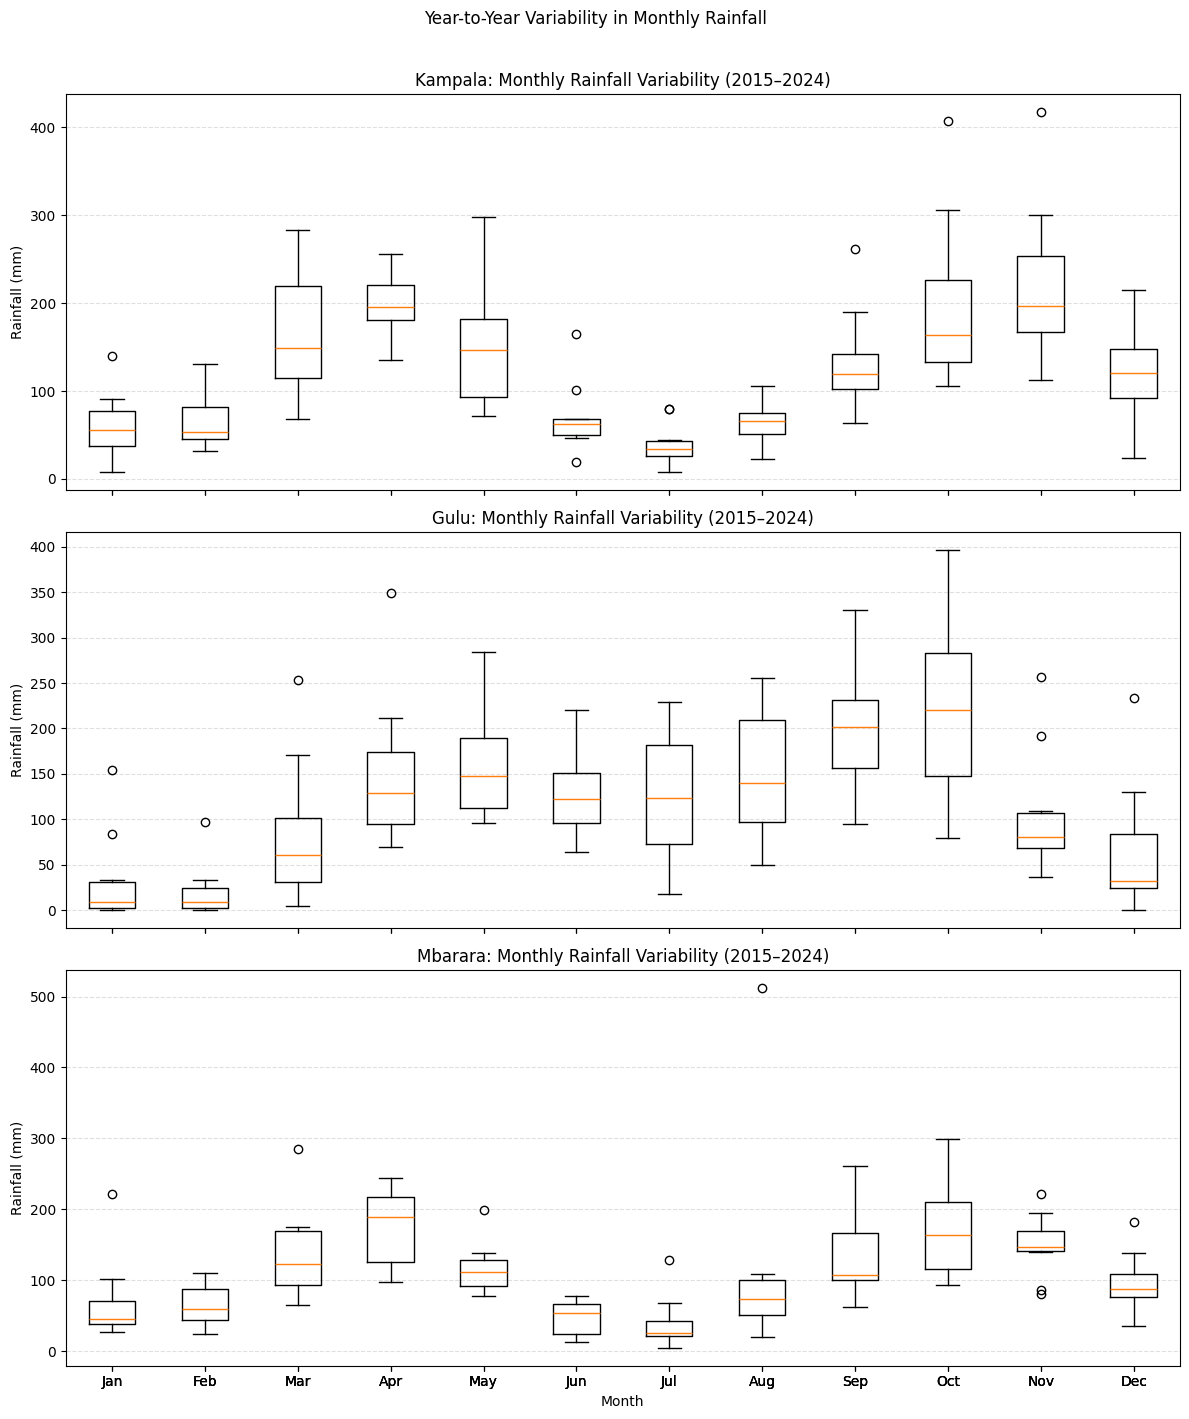

In [15]:

# Convert the monthly index into separate Year and Month columns
rainfall_long = real_rainfall_df.reset_index(names="Date")

rainfall_long["Year"] = rainfall_long["Date"].dt.year
rainfall_long["Month"] = rainfall_long["Date"].dt.month
rainfall_long["Month_name"] = rainfall_long["Date"].dt.strftime("%b")

# Create one box plot per region
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 14),
    sharex=True
)

for ax, region_name in zip(axes, real_rainfall_df.columns):
    monthly_groups = [
        rainfall_long.loc[
            rainfall_long["Month"] == month_number,
            region_name
        ].dropna().to_numpy()
        for month_number in range(1, 13)
    ]

    ax.boxplot(monthly_groups, tick_labels=months)

    ax.set_title(f"{region_name}: Monthly Rainfall Variability (2015–2024)")
    ax.set_ylabel("Rainfall (mm)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Month")

plt.suptitle(
    "Year-to-Year Variability in Monthly Rainfall",
    y=1.01
)
plt.tight_layout()
plt.show()


In [16]:

monthly_variability = rainfall_long.melt(
    id_vars=["Date", "Year", "Month", "Month_name"],
    value_vars=list(real_rainfall_df.columns),
    var_name="Region",
    value_name="Rainfall_mm"
)

variability_summary = (
    monthly_variability
    .groupby(["Region", "Month_name"], sort=False)["Rainfall_mm"]
    .agg(
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max"
    )
    .round(2)
)

display(variability_summary)


Mean  Median  Std_Dev  Minimum  Maximum
Region  Month_name                                           
Kampala Jan          60.27   55.26    37.42     7.80   139.91
        Feb          68.07   52.81    35.51    31.89   130.41
        Mar         163.76  149.51    74.13    68.02   283.42
        Apr         199.20  195.33    36.53   135.41   255.93
        May         152.20  147.14    70.48    71.64   297.71
        Jun          69.69   62.22    39.44    18.94   165.36
        Jul          40.03   34.50    22.90     8.36    79.42
        Aug          66.17   66.17    25.21    23.11   106.06
        Sept        133.00  119.12    56.43    64.07   261.47
        Oct         195.02  164.04    96.88   105.81   407.17
        Nov         220.89  197.04    87.54   112.60   417.22
        Dec         121.20  120.24    54.39    24.08   215.14
Gulu    Jan          31.52    8.28    50.12     0.15   154.22
        Feb          19.60    8.69    29.18     0.37    96.52
        Mar          81.51   60.75    78.26     3.96   252.94
        Apr         150.30  129.24    82.74    69.16   348.98
        May         160.62  147.60    63.41    95.40   283.81
        Jun         131.71  122.02    52.41    64.14   220.82
        Jul         125.70  123.89    69.18    17.89   229.04
        Aug         151.82  140.15    69.79    49.66   255.10
        Sept        200.93  201.50    67.56    94.47   330.67
        Oct         221.41  220.20    95.11    79.28   396.35
        Nov         104.29   80.72    68.67    36.18   256.46
        Dec          62.37   31.91    72.85     0.30   233.99
Mbarara Jan          68.18   45.95    58.92    26.73   222.41
        Feb          63.27   59.02    29.90    24.45   111.02
        Mar         138.73  123.09    65.18    65.55   285.35
        Apr         175.92  189.09    53.00    97.72   243.95
        May         116.78  111.35    35.61    77.76   199.16
        Jun          47.36   54.04    24.18    13.25    77.42
        Jul          39.27   25.59    36.09     5.06   129.03
        Aug         113.10   73.76   142.83    20.04   511.95
        Sept        138.42  107.73    69.70    61.99   261.67
        Oct         171.97  164.20    67.12    93.30   299.59
        Nov         149.92  147.26    43.57    80.28   221.63
        Dec          93.61   87.77    43.79    36.38   182.87

The NASA POWER rainfall estimates for 2015–2024 reveal differences in monthly rainfall distributions and year-to-year variability across Kampala, Gulu, and Mbarara. Kampala recorded its highest mean monthly rainfall in November (220.89 mm), while Gulu's highest mean occurred in October (221.41 mm). Mbarara had its highest mean in April (175.92 mm). July was the driest month on average in Kampala and Mbarara, whereas February was the driest in Gulu. The box plots show how rainfall in a given calendar month varies between years, while the standard deviations and minimum–maximum ranges quantify this variability. These differences demonstrate why agricultural planning should consider both seasonal rainfall patterns and year-to-year uncertainty. However, the analysis uses NASA POWER gridded precipitation estimates at representative coordinates, which may differ from measurements at local rain gauges. The findings should therefore be interpreted as estimates for the selected locations and period rather than definitive long-term climate normals.